<a href="https://colab.research.google.com/github/LACDR-CDS/SCDR_RNAseq/blob/main/Session3and4/group1_solution_NKX2_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 3 & 4
In the last session, you learned the basic processing steps for RNA sequencing data. Now you will do the next steps in the analysis of transcriptomics data to investigate how loss of *NKX2-5* affects gene expression during human cardiomyocyte differentiation.

Background

## Background
*NKX2-5* is a key transcription factor involved in heart development, regulating genes required for cardiomyocyte differentiation and function. Mutations in *NKX2-5* are associated with *congenital heart defects* and *cardiac conduction abnormalities*.

To investigate its role, researchers generated *NKX2-5 knockout (KO)* human embryonic stem cells, in which both copies of the gene were disrupted, resulting in loss of *NKX2-5* function. These cells and their isogenic controls were differentiated towards cardiomyocytes.

In this session, you will analyze RNA-seq data from *day 10* of cardiac differentiation, comparing *NKX2-5 KO* and *control cells* to investigate how the absence of *NKX2-5* affects cardiac gene expression.

## Objectives

1. Explore whether *NKX2-5 KO* mutation alters global gene expression patterns (PCA).  
2. Identify differentially expressed genes (DEGs) between KO and control.
3. Visualize DEGs with volcano plots and heatmaps.  
4. Perform GO enrichment to determine affected biological pathways.  
5. Interpret whether *NKX2-5* loss of function affects cardiomyocyte differentiation, maturation, and cardiac-specific gene expression.

## Setup

Run the following cells to set up the necessary packages and download the data. If you wish to use a package which is not in the list below, you will need to install and import it yourself.

In [1]:
#Install packages which are not in the default environment
%pip install pydeseq2
%pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.8 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [pydeseq2]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.0/693.0 kB 11.1 MB/s  0:00:00


In [3]:
#Import packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import anndata as ad
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import pickle
import gseapy
import os
import warnings
warnings.filterwarnings("ignore")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [18]:
group_number = 1

#Make data directory if it does not exist
os.makedirs("data", exist_ok=True)
os.makedirs("plots", exist_ok=True)

#Download datasets in the data folder
!wget https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group{group_number}_counts.csv -O data/group{group_number}_counts.csv
!wget https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group{group_number}_metadata.csv -O data/group{group_number}_metadata.csv

--2026-11-19 13:58:52--  https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group1_counts.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1152502 (1.1M) [text/plain]
Saving to: ‘data/group1_counts.csv’

data/group1_counts. 100%[===================>]   1.10M  --.-KB/s    in 0.02s   

2026-11-19 13:58:53 (55.1 MB/s) - ‘data/group1_counts.csv’ saved [1152502/1152502]

--2026-11-19 13:58:53--  https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group1_metadata.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.c

## Data import
Read in your counts and metadata table like you learned in session 2.
- How many samples and genes do you have?

Read the corresponding metadata table.
- Which differentiation day do the samples belong to?

**Solution**<br/>
There are 2 samples (isogenic/control, KO) and 3 replicated and 43079 genes. The samples belong to differentiation day 10.

### ANSWER CODE

In [19]:
# Load data
counts = pd.read_csv("data/group1_counts.csv", index_col=0)
metadata = pd.read_csv("data/group1_metadata.csv", index_col = ['sample_id'])
print(counts)
print (metadata)

             NKX2-5_Ctrl_1  NKX2-5_Ctrl_2  NKX2-5_Ctrl_3  NKX2-5_KO_1  \
DDX11L1                  0              0              0            0   
WASH7P                  63             79             70           62   
MIR6859-1               11             11              6            8   
MIR1302-2HG              4              2              2            4   
MIR1302-2                0              0              0            0   
...                    ...            ...            ...          ...   
ND6                  23402          27935          28974        22308   
TRNE                     0              0              0            0   
CYTB                 61345          59590          70895        40427   
TRNT                     1              0              0            0   
TRNP                  1267           1351           1279          748   

             NKX2-5_KO_2  NKX2-5_KO_3  
DDX11L1                0            0  
WASH7P                74           59  
MIR

## Filtering
Filter the data to remove genes with less than 10 reads over all samples.
- How many genes are left in the count table after filtering?

**Solution**<br/>
There are 22599 genes left after filtering.

In [20]:
counts = counts[counts.sum(axis=1) >= 10]
print(counts)

              NKX2-5_Ctrl_1  NKX2-5_Ctrl_2  NKX2-5_Ctrl_3  NKX2-5_KO_1  \
WASH7P                   63             79             70           62   
MIR6859-1                11             11              6            8   
MIR1302-2HG               4              2              2            4   
LOC124900384              4              9              3           10   
LOC729737               661            821            743          830   
...                     ...            ...            ...          ...   
ND4                  151857         157575         172176       124014   
ND5                   77500          90028          98180        70684   
ND6                   23402          27935          28974        22308   
CYTB                  61345          59590          70895        40427   
TRNP                   1267           1351           1279          748   

              NKX2-5_KO_2  NKX2-5_KO_3  
WASH7P                 74           59  
MIR6859-1               7    

### ANSWER CODE

In [21]:
counts = counts[counts.sum(axis=1) >= 10]
print(counts)

              NKX2-5_Ctrl_1  NKX2-5_Ctrl_2  NKX2-5_Ctrl_3  NKX2-5_KO_1  \
WASH7P                   63             79             70           62   
MIR6859-1                11             11              6            8   
MIR1302-2HG               4              2              2            4   
LOC124900384              4              9              3           10   
LOC729737               661            821            743          830   
...                     ...            ...            ...          ...   
ND4                  151857         157575         172176       124014   
ND5                   77500          90028          98180        70684   
ND6                   23402          27935          28974        22308   
CYTB                  61345          59590          70895        40427   
TRNP                   1267           1351           1279          748   

              NKX2-5_KO_2  NKX2-5_KO_3  
WASH7P                 74           59  
MIR6859-1               7    

## Normalization: counts per million
Perform normalization to account for differences in sequencing depth among samples.

### ANSWER CODE

In [22]:
total_reads = counts.sum(axis = 0)
normalized_count_table = (counts / total_reads) * 1e6
log_transformed_counts = np.log2(normalized_count_table + 1)

## Principle component analysis (PCA)

Now explore your data with PCA like you did in the previous session. Plot the first two principal components, use the seaborn package.
- Does the knock out of *NKX2-5* have any effect on gene expression or do all samples cluster together?
- Do you think the control samples of the are perfect replicates? What about the gene knock out samples?

**Solution**<br/>
The mutation has an effect on gene expression, as the PCA plot shows that the KO and control samples cluster separately. However, there is also quite a transcriptional difference between the knock-out samples, which makes them less reliable as replicates. The control samples cluster a lot closer together, which makes them better replicates.

### ANSWER CODE

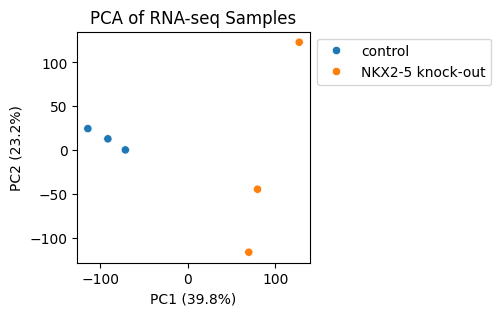

In [23]:
scaler = StandardScaler()
scaled_table = scaler.fit_transform(log_transformed_counts.T)
pca = PCA()
pca_result_matrix = pca.fit_transform(scaled_table)
np.shape(pca_result_matrix)

plot_df = pd.DataFrame({
 "PC1": pca_result_matrix[:, 0],
 "PC2": pca_result_matrix[:, 1],
 "condition": metadata["condition"].values
})

plt.figure(figsize=(3, 3))

sns.scatterplot(
data=plot_df,
x="PC1", y="PC2",
hue="condition"
)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of RNA-seq Samples")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

## Differential gene expression

Now you can perform differential gene expression analysis using the DEseq2 method. This method allows to find genes with significant expression differences (up- or downregulated) between two conditions.
- Your goal is to investigate the effect of the mutation on cardiomyocyte differentiation. Which samples do you need to compare?
- Build your DEseq object(s) and run the analysis. *Make sure you use the raw filtered counts for this (not the counts per million normalized counts used for PCA), since DEseq does it's own internal normalization method.*
- Look at the results of you analysis. What information do the rows and columns of the DEseq result mean?

**Solution**<br/>
We need to compare the missense mutation with the isogenic wildtype. The rows are the gene names and the columns show the statistical differential expression results.
- baseMean: mean normalized expression across all samples.
- log2FoldChange: log₂ of the estimated fold change between conditions.
- lfcSE: standard error of the log2FoldChange estimate.
- stat: Wald test statistic (log2FoldChange / lfcSE).
- pvalue: p-value for H₀: log2FoldChange = 0.
- padj: p-value adjusted for multiple testing (FDR, e.g. Benjamini–Hochberg).

### ANSWER CODE

In [24]:
dds = DeseqDataSet(counts=counts.T, metadata= metadata, design_factors="condition")
dds.deseq2()
stat_res = DeseqStats(
    dds,
    contrast=("condition","NKX2-5 knock-out","control")
)
stat_res.summary()
res_df = stat_res.results_df

Log2 fold change & Wald test p-value: condition NKX2-5 knock-out vs control
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
WASH7P            67.312377       -0.041561  0.258525 -0.160762  0.872281   
MIR6859-1          9.404398        0.108495  0.643640  0.168564  0.866139   
MIR1302-2HG        2.848107        0.245947  1.103652  0.222848  0.823654   
LOC124900384       5.887225        0.348492  0.851562  0.409239  0.682365   
LOC729737        756.648034        0.154514  0.157933  0.978353  0.327900   
...                     ...             ...       ...       ...       ...   
ND4           155615.422772        0.010727  0.133509  0.080348  0.935961   
ND5            86449.205441        0.034617  0.136417  0.253762  0.799679   
ND6            26549.175923        0.079133  0.140874  0.561729  0.574301   
CYTB           61255.962906       -0.023182  0.206902 -0.112046  0.910787   
TRNP            1055.537752       -0.554299  0.222752 -2.488411  0.012832   


- Now get the significantly upregulated and downregulated genes from this dataframe with a log2 fold change bigger than 2. Are there more genes that are upregulated or downregulated? _Tip: to get an overview in one figure, you can plot the upregulated and downregulated genes in a volcano plot._

**Solution**<br/>
There are more genes upregulated (360) than downregulated (188).

### ANSWER CODE

In [25]:
upregulated_genes = res_df[(res_df["log2FoldChange"] > 2) & (res_df["padj"] < 0.05)]
upregulated_genes

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
TNFRSF9,9.801018,2.933595,0.928365,3.159957,1.577922e-03,1.281917e-02
ALPL,21.756991,2.199229,0.503213,4.370374,1.240339e-05,2.081372e-04
GJA4,13.559107,2.885918,0.646578,4.463373,8.067956e-06,1.421968e-04
EPHA10,53.542925,2.366839,0.395333,5.986945,2.138185e-09,8.258689e-08
HEYL,57.127005,2.442219,0.399129,6.118869,9.424197e-10,3.948859e-08
...,...,...,...,...,...,...
DCX,561.311026,3.373875,0.197114,17.116380,1.120296e-65,4.474237e-62
RAB33A,29.568978,2.343270,0.627612,3.733632,1.887384e-04,2.200186e-03
GPC3,5815.879880,2.792699,0.449270,6.216077,5.097384e-10,2.272091e-08
MAMLD1,133.767371,4.845261,0.341964,14.168914,1.426898e-45,1.899582e-42


In [26]:
downregulated_genes = res_df[(res_df["log2FoldChange"] < -2) & (res_df["padj"] < 0.05)]
downregulated_genes

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
TMEM52,21.510387,-2.021047,0.671437,-3.010033,2.612191e-03,1.924635e-02
LOC124903827,372.619806,-5.695040,0.614079,-9.274113,1.791023e-20,3.406185e-18
PRDM16,515.463371,-4.838740,0.277738,-17.421959,5.621863e-68,2.806574e-64
LOC107984909,8.618004,-3.199224,0.889777,-3.595535,3.237256e-04,3.466960e-03
LOC124903828,21.924632,-4.625916,0.765511,-6.042909,1.513598e-09,6.106070e-08
...,...,...,...,...,...,...
LOC105379548,6.107077,-6.026600,2.063896,-2.920011,3.500186e-03,2.434525e-02
MAOA,93.351413,-2.356213,0.384466,-6.128538,8.869025e-10,3.736404e-08
POF1B,8.666724,-2.213953,0.744678,-2.973033,2.948726e-03,2.112777e-02
SYTL4,198.585759,-3.548885,0.310078,-11.445135,2.487174e-30,9.197476e-28


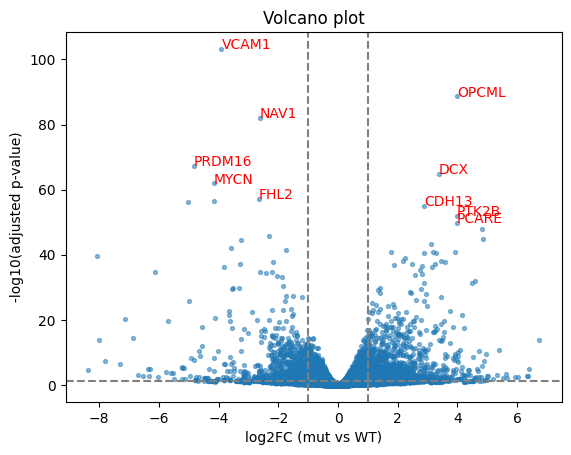

In [28]:
plt.scatter(res_df.log2FoldChange, -np.log10(res_df.pvalue), s=8, alpha=0.5)

plt.axhline(-np.log10(0.05), ls="--", color="grey")
plt.axvline(1, ls="--", color="grey")
plt.axvline(-1, ls="--", color="grey")

plt.xlabel("log2FC (mut vs WT)")
plt.ylabel("-log10(adjusted p-value)")
plt.title(f"Volcano plot")

up = res_df[res_df.log2FoldChange > 1].nsmallest(5, "pvalue")
down = res_df[res_df.log2FoldChange < -1].nsmallest(5, "pvalue")

for gene, r in up.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")
for gene, r in down.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")

plt.show()


- What are the 3 most up-regulated and down-regulated genes you can see the volcano plot?
- What about the 10 most significant differentially expressed genes (*hint: sort the resulting dataframe by p-adjusted value (padj), then look at the first 10 rows of the sorted dataframe (res_df.head(10).index)*? Can you plot these in a heatmap?
- What are the functions of these genes?
- Can you find literature to link these to the *NKX2.5* knock-out?


**Solution**<br/>
downregulated:
- VCAM: Mediates cell adhesion and inflammatory signalling; used as a marker to identify hPSC-derived cardiomyocytes
- NAV1: nervous system development, neuronal migration, and microtubule cytoskeleton organization.
- PRDM16: Transcriptional regulator involved in cell fate determination, cardiac development, and metabolic regulation. Important for ventricular cardiomyocyte identity and cardiac morphogenesis.
- MYCN:Transcription factor controlling cell proliferation, growth, and developmental programs. Important for cardiomyocyte proliferation during embryonic heart development.
- FHL2:Scaffold protein involved in cardiac sarcomere organization, mechanotransduction, and transcriptional regulation. Interacts with proteins associated with muscle contraction.
- HEY2: Transcriptional repressor downstream of the Notch signaling pathway involved in cardiac development, particularly ventricular specification and cardiomyocyte maturation. It is an important downstream component of the NKX2-5 regulatory network.
- AHNAK2: Large scaffold protein associated with cytoskeletal organization, membrane structure, and cellular signaling. Its downregulation may reflect changes in cardiomyocyte structural organization and development.

upregulated:
- OPCML: cell adhesion protein involved in cell-cell interactions, particularly in the nervous system.
- DCX:  doublecortin protein, which is essential for guiding developing neurons to their proper positions in the brain (neuronal migration)
- CHD13: Cell adhesion protein involved in vascular development, cardiovascular signaling, and neuronal connectivity
- PTK2B: protein tyrosine kinase, involved in calcium-induced regulation of ion channels
- PCARE:  regulates actin dynamics to build and renew light-sensitive outer segment disks
- CDH13: Encodes T-cadherin, a cell adhesion protein involved in cardiovascular development, vascular signaling, and neuronal connectivity.


**Interpretation:**

NKX2-5 is a key transcription factor regulating cardiac differentiation and ventricular specification. Its knockout leads to downregulation of genes involved in cardiac development (**PRDM16, MYCN**), cardiomyocyte adhesion (**VCAM1**), and structural organization (**FHL2**), suggesting disruption of normal cardiac differentiation.

At the same time, genes associated with neuronal development and cell migration (**DCX, OPCML**) are upregulated, suggesting dysregulation of alternative developmental programs.

Downregulation of HEY2, together with other cardiac developmental genes, suggests that NKX2-5 knockout may disrupt ventricular specification and cardiomyocyte differentiation rather than completely preventing cardiac lineage commitment.

### ANSWER CODE

In [31]:
res_df = res_df.sort_values('padj')
top10 = res_df.head(10).index
top10


Index(['VCAM1', 'OPCML', 'NAV1', 'PRDM16', 'DCX', 'MYCN', 'FHL2', 'HEY2',
       'AHNAK2', 'CDH13'],
      dtype='str')

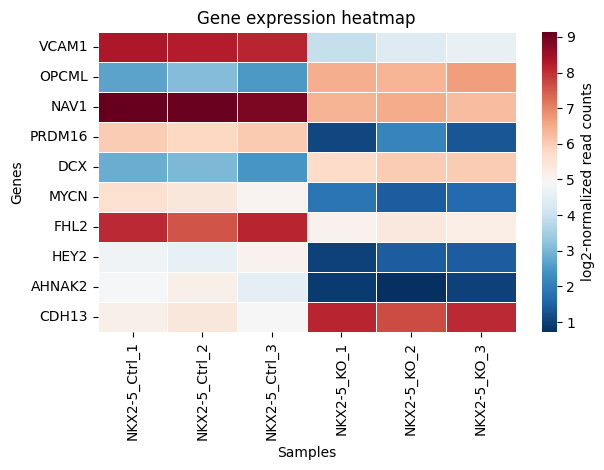

In [30]:
sns.heatmap(
log_transformed_counts.loc[top10],
cmap="RdBu_r",
linecolor = "white",
linewidth = 0.5,
cbar_kws={"label": "log2-normalized read counts"}
)
plt.title("Gene expression heatmap")
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.tight_layout()
plt.show()


# Gene Ontology enrichment

Now, you can start interpreting the lists of genes you get from the DEseq analysis and learn if there are any biological pathways that are effected by the *NKX2.5* knock-out.
- Use the cheat sheet to perform a GO enrichment analysis on the downregulated and upregulated genes. Which biological processes are upregulated and downregulated in mutant vs WT at this day?
- Can you find scientific evidence in literature that these processes are regulated by *NKX2.5*?

### ANSWER CODE

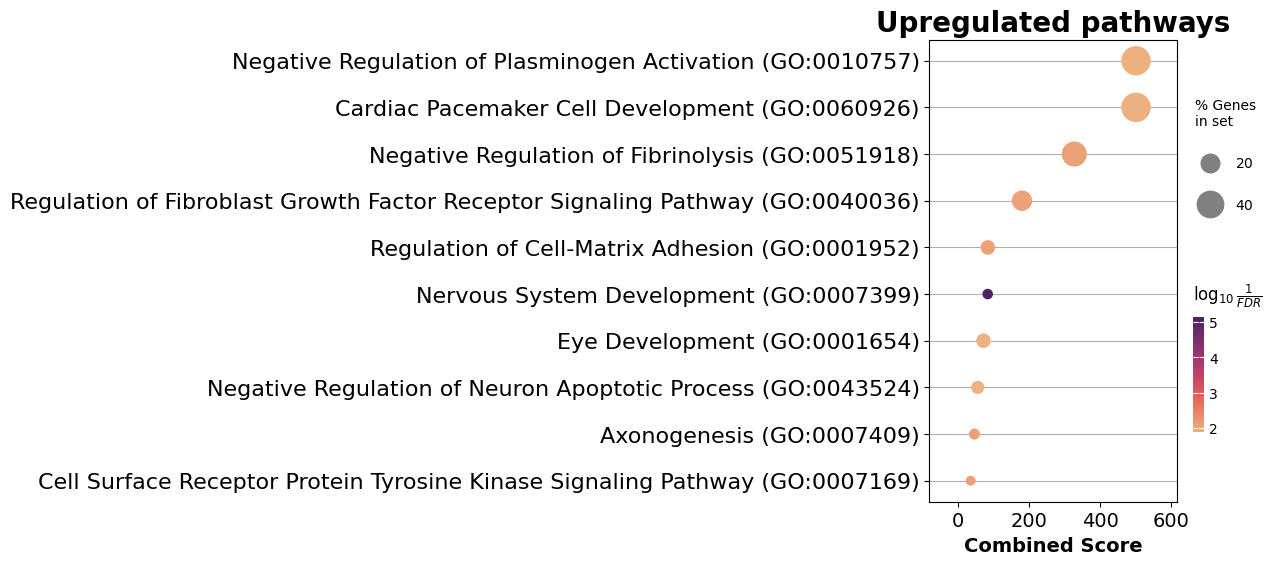

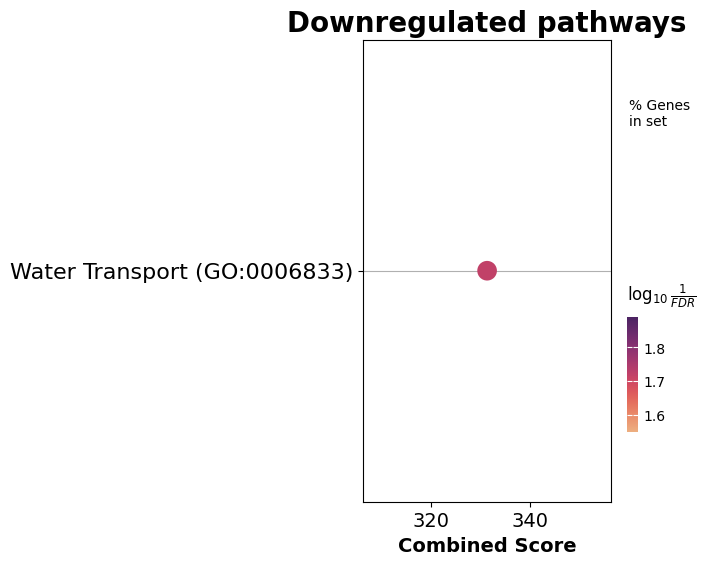

In [34]:
up   = upregulated_genes.index.tolist()
down = downregulated_genes.index.tolist()

enr_up = gseapy.enrichr(up,
                        gene_sets=["GO_Biological_Process_2025"],
                        organism="human", cutoff=0.05)
gseapy.plot.dotplot(enr_up.res2d, title=f"Upregulated pathways", cmap="flare", top_term=10)
plt.show()

enr_down = gseapy.enrichr(down,
                          gene_sets=["GO_Biological_Process_2025"],
                          organism="human", cutoff=0.05)
gseapy.plot.dotplot(enr_down.res2d, title=f"Downregulated pathways", cmap="flare", top_term=10)
plt.show()

NKX2-5 knockout alters cardiac cell specification and activates alternative developmental programs, rather than simply preventing cardiac differentiation.

NKX2-5 is involved in establishing cardiac chamber identity, including ventricular specification.HEY2 downregulation, together with enrichment of genes associated with pacemaker cell development, suggests a possible shift in cardiac subtype-specific gene expressio,  potentially shifting gene expression away from a ventricular program towards a more pacemaker-like program.